# MAGIC imputation (ArchR `addImputeWeights` / `imputeMatrix`)

scATAC gene scores are extremely sparse: most cells have zero signal for any
single gene, so a raw gene-score UMAP looks like salt-and-pepper noise. ArchR
smooths these values with **MAGIC** (van Dijk et al., *Cell* 2018): every cell
is replaced by a weighted average of its neighbours in the reduced-dimension
space.

`epi.tl.add_impute_weights` and `epi.tl.impute_matrix` are line-by-line ports
of ArchR's `addImputeWeights` and `imputeMatrix` (ArchR 1.0.3,
`R/Imputation.R`). They are checked against ArchR on the same data at the end
of this notebook.

```{note}
`scanpy.external.pp.magic` only calls the separate `magic-impute` package; scanpy
itself contains no MAGIC algorithm. The specification ported here is ArchR's own
adaptation, which differs from `magic-impute` (random cell blocks, self-loops,
`W^(td+1)` diffusion, averaging over replicates), so Epione does not depend on
either package.
```

## What ArchR computes

For each of `n_rep` replicates the cells are shuffled and cut into blocks of
about `sample_cells` cells. Inside each block:

1. find the `k` nearest neighbours of every cell (the cell itself counts as
   neighbour 1) on the reduced dimensions;
2. **autotune**: divide each cell's distances by the distance to its `ka`-th
   neighbour, so dense and sparse regions get a comparable kernel width;
3. build the symmetric kernel $W = \exp\!\big(-(D + D^\top)/\epsilon^2\big)$ on
   the kNN pattern. The zero self-distance is kept, so every cell carries a
   self-loop of weight 1;
4. Markov-normalise the rows and diffuse: $W_t = W^{\,td+1}$.

`impute_matrix` multiplies each block operator into its cells' values and
averages the replicates.

## Setup — ArchR Hematopoiesis tutorial data

In [1]:
import json, pathlib, sys, time
import numpy as np
import pandas as pd
import anndata as ad
import scipy.io
import matplotlib as mpl
import matplotlib.pyplot as plt
from IPython.display import display, Image
import epione as epi

FIX = pathlib.Path('/scratch/users/steorra/analysis/25_epione/epione_dev/fixture/tables')
REF = pathlib.Path('/scratch/users/steorra/analysis/25_epione/epione_dev/work/impute-magic/ref')
epi.__file__

'/scratch/users/steorra/analysis/25_epione/epione_dev/wt/impute-magic/epione/__init__.py'

The fixture is the ArchR tutorial project (`getTutorialData("Hematopoiesis")`:
BMMC, CD34+ BMMC and PBMC, 10,660 cells) with its `IterativeLSI`, `UMAP`,
`Clusters` and `GeneScoreMatrix` exported from ArchR. `lsi.tsv` is exactly
what ArchR's `getReducedDims()` hands to `addImputeWeights` (row z-scored LSI,
depth-correlated dimensions removed), so we pass it as-is.

In [2]:
%%time
cells = pd.read_csv(FIX / 'cells.tsv', sep='\t', index_col=0)
lsi = pd.read_csv(FIX / 'lsi.tsv', sep='\t', index_col=0)
gs = scipy.io.mmread(FIX / 'GeneScoreMatrix.mtx').T.tocsr()          # cells x genes
gs_cells = pd.read_csv(FIX / 'GeneScoreMatrix_cells.txt', header=None)[0].to_numpy()
genes = pd.read_csv(FIX / 'GeneScoreMatrix_features.tsv', sep='\t')['name'].to_numpy()

adata = ad.AnnData(X=gs, obs=cells.loc[gs_cells].copy())
adata.var_names = genes
adata.obsm['X_iterative_lsi'] = lsi.loc[adata.obs_names].to_numpy()
adata.obsm['X_umap'] = adata.obs[['UMAP1', 'UMAP2']].to_numpy()
adata

CPU times: user 2.21 s, sys: 493 ms, total: 2.7 s
Wall time: 896 ms


AnnData object with n_obs × n_vars = 10660 × 23127
    obs: 'Sample', 'TSSEnrichment', 'ReadsInTSS', 'ReadsInPromoter', 'ReadsInBlacklist', 'PromoterRatio', 'PassQC', 'NucleosomeRatio', 'nMultiFrags', 'nMonoFrags', 'nFrags', 'nDiFrags', 'BlacklistRatio', 'Clusters', 'ReadsInPeaks', 'FRIP', 'UMAP1', 'UMAP2'
    obsm: 'X_iterative_lsi', 'X_umap'

## Compute impute weights

In [3]:
%%time
epi.tl.add_impute_weights(
    adata,
    use_rep='X_iterative_lsi',
    sample_cells=5000,   # ArchR defaults
    n_rep=2,
    k=15, td=3, ka=4, epsilon=1,
    seed=1,              # rng='R' (default) gives the same blocks as ArchR, threads = 1
)
iw = adata.uns['impute_weights']
[(len(rep), [len(b['cells']) for b in rep]) for rep in iw['weights']]

  └─ [add_impute_weights] replicate 1/2: 2 block(s) of ~5,331 cells


  └─ [add_impute_weights] replicate 2/2: 2 block(s) of ~5,331 cells


CPU times: user 4.58 s, sys: 514 ms, total: 5.1 s
Wall time: 5.1 s


[(2, [5331, 5329]), (2, [5331, 5329])]

Every block operator is row-stochastic, and every cell keeps some of its own
signal through the self-loop:

In [4]:
W = iw['weights'][0][0]['weights']
print('shape', W.shape, '| row sums', W.sum(1).min().round(12), W.sum(1).max().round(12))
print('fraction non-zero', round((W > 0).mean(), 3), '| median self weight', round(np.median(np.diag(W)), 4))

shape (5331, 5331) | row sums 1.0 1.0
fraction non-zero 0.326 | median self weight 0.0116


## Impute marker gene scores

In [5]:
%%time
markers = ['CD34', 'GATA1', 'PAX5', 'MS4A1', 'CD14', 'CD3D']
imputed = epi.tl.impute_matrix(adata, genes=markers)
raw = adata[:, markers].X.toarray()
imputed.shape

CPU times: user 384 ms, sys: 20.6 ms, total: 404 ms
Wall time: 152 ms


(10660, 6)

### Raw vs imputed gene scores on the UMAP

Same styling as ArchR `plotEmbedding(colorBy = "GeneScoreMatrix")`:
`log2(x + 1)`, values clipped to the 1–99 % quantiles, `horizonExtra` palette.

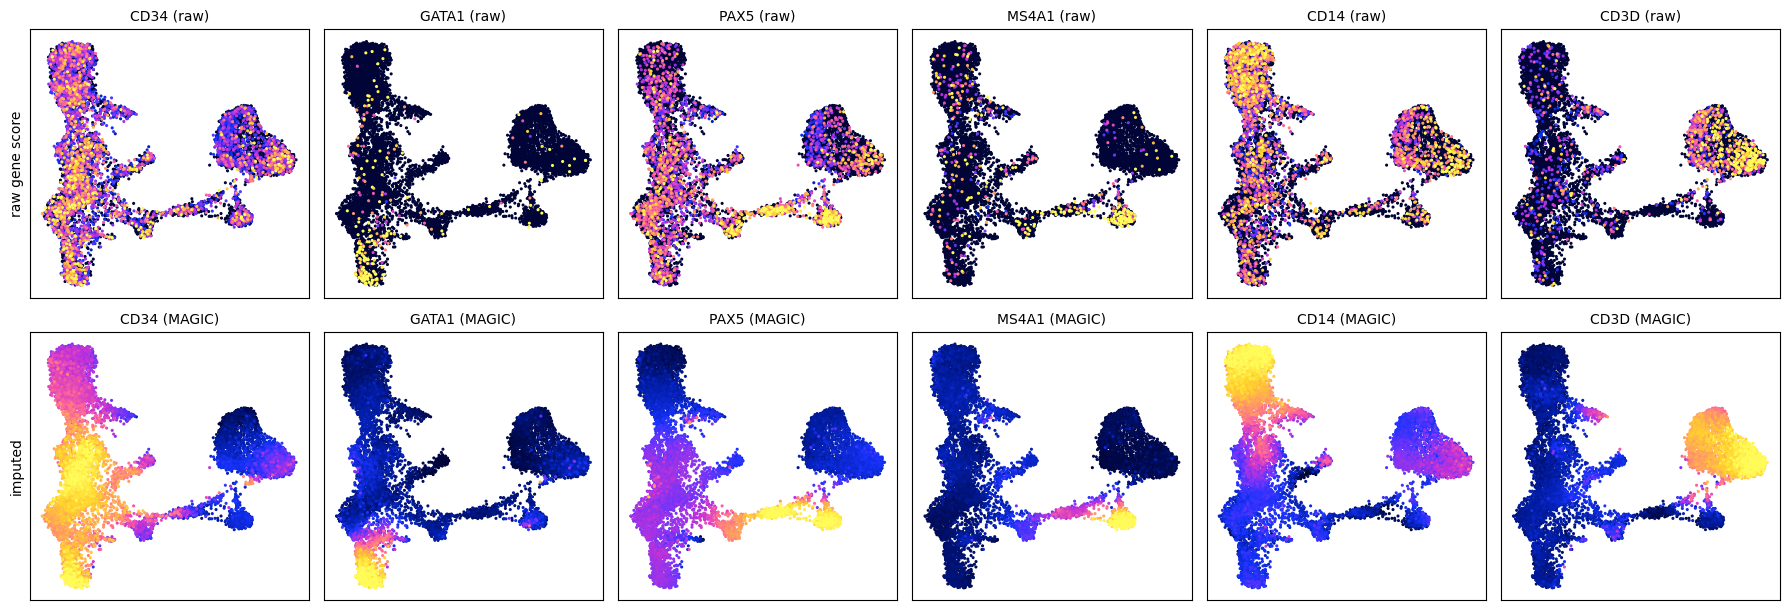

In [6]:
HORIZON = mpl.colors.LinearSegmentedColormap.from_list('horizonExtra', [
    '#000436', '#021EA9', '#1632FB', '#6E34FC', '#C732D5',
    '#FD619D', '#FF9965', '#FFD32B', '#FFFC5A'])

def qcut(x, lo=0.01, hi=0.99):
    q = np.quantile(x, [lo, hi])
    if q[1] == 0:
        q[1] = x.max()
    return np.clip(x, q[0], q[1])

umap = adata.obsm['X_umap']
fig, axes = plt.subplots(2, len(markers), figsize=(3 * len(markers), 6.2))
for j, g in enumerate(markers):
    for i, (lab, M) in enumerate([('raw', raw), ('MAGIC', imputed)]):
        v = qcut(np.log2(M[:, j] + 1))
        o = np.argsort(v)
        ax = axes[i, j]
        ax.scatter(umap[o, 0], umap[o, 1], c=v[o], cmap=HORIZON, s=1.5, rasterized=True)
        ax.set_title(f'{g} ({lab})', fontsize=10); ax.set_xticks([]); ax.set_yticks([])
axes[0, 0].set_ylabel('raw gene score'); axes[1, 0].set_ylabel('imputed')
plt.tight_layout(); plt.show()

### Plotting through `epi.pl.embedding`

`impute_matrix(..., layer_added=...)` stores the imputed values as a layer
(when every feature is imputed), which is the analogue of ArchR's
`plotEmbedding(imputeWeights = getImputeWeights(proj))`. Imputing all 23k genes
is a ~2 GB dense matrix, so here we do it on a marker-only AnnData that carries
the same weights.

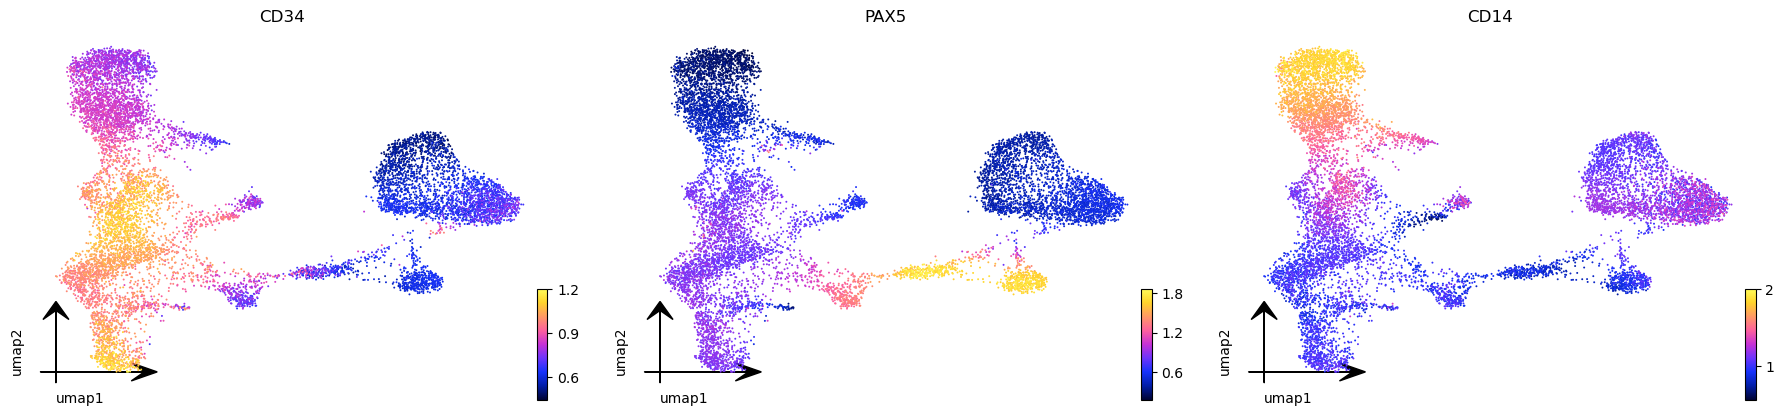

In [7]:
sub = adata[:, markers].copy()
_ = epi.tl.impute_matrix(sub, layer_added='magic')
sub.layers['magic'] = np.log2(sub.layers['magic'] + 1)   # ArchR log2-normalises after imputing
epi.pl.embedding(sub, basis='X_umap', color=['CD34', 'PAX5', 'CD14'], layer='magic',
                 cmap=HORIZON, frameon=False, ncols=3, size=8)

## Parity vs ArchR

`tests/parity/impute_magic/r_reference.R` runs ArchR 1.0.3 on the same project
(`threads = 1`, `useHdf5 = FALSE`) and dumps the reduced dimensions, the
sampled blocks, every block's diffusion matrix and the imputed gene scores of a
99-gene panel (6 markers + every 250th gene). `parity_check.py` compares three
modes against it; thresholds were registered in `MANIFEST.md` before the first
comparison.

* **injected** — ArchR's sampled blocks are passed through `blocks=`;
* **rng="R"** — Epione draws the blocks itself with its emulation of R's
  `set.seed()` + `sample()`;
* **rng="numpy"** — an unrelated random blocking, compared with the
  correlation metric next to ArchR seed 1 vs ArchR seed 2.

In [8]:
%%time
sys.path.insert(0, str(pathlib.Path(epi.__file__).parents[1] / 'tests' / 'parity' / 'impute_magic'))
import parity_check
res = parity_check.main(str(REF))

{
  "reduced_dims_max_abs_err": 0.0,
  "injected_blocks_identical": true,
  "injected_weights_max_abs_err": 5.551115123125783e-17,
  "injected_imputed_max_abs_err": 1.0658141036401503e-14,
  "injected_imputed_max_rel_err": 2.180864795669628e-15,
  "timing_weights_s": 5.055410861968994,
  "timing_impute_s": 0.3422269821166992,
  "rngR_blocks_identical": true,
  "rngR_weights_max_abs_err": 5.551115123125783e-17,
  "rngR_imputed_max_abs_err": 1.0658141036401503e-14,
  "rngR_imputed_max_rel_err": 2.180864795669628e-15,
  "numpy_median_gene_pearson": 0.9167910218167196,
  "numpy_min_gene_pearson": 0.482821208084191,
  "archr_seed1_vs_seed2_median_gene_pearson": 0.913184532468051,
  "archr_seed1_vs_seed2_min_gene_pearson": 0.5392858129363761,
  "n_genes": 99,
  "n_cells": 10660
}
CPU times: user 20.1 s, sys: 5.29 s, total: 25.4 s
Wall time: 21.9 s


In [9]:
rows = [
    ('Reduced dims fed to MAGIC', 'deterministic', '1', 'max |Δ|', '≤ 1e-6', res['reduced_dims_max_abs_err']),
    ('Block membership', 'R draws injected', '1', 'identical', 'True', res['injected_blocks_identical']),
    ('Diffusion weights W^(td+1)', 'R draws injected', '1', 'max |Δ|', '≤ 1e-6', res['injected_weights_max_abs_err']),
    ('Imputed gene panel', 'R draws injected', '1', 'max |Δ| / max|x|', '≤ 1e-6', res['injected_imputed_max_rel_err']),
    ('Block membership', 'free-running rng="R"', '1', 'identical', 'True', res['rngR_blocks_identical']),
    ('Diffusion weights', 'free-running rng="R"', '1', 'max |Δ|', '≤ 1e-6', res['rngR_weights_max_abs_err']),
    ('Imputed gene panel', 'free-running rng="R"', '1', 'max |Δ|', '≤ 1e-6', res['rngR_imputed_max_abs_err']),
    ('Imputed gene panel', 'free-running rng="numpy"', '2/6', 'median gene Pearson', '≥ 0.95', res['numpy_median_gene_pearson']),
    ('  (ArchR seed 1 vs seed 2)', 'baseline', '', 'median gene Pearson', '', res['archr_seed1_vs_seed2_median_gene_pearson']),
]
def gate(thr, v):
    if thr == '':
        return ''
    if thr == 'True':
        return 'PASS' if v else 'FAIL'
    op, x = thr.split()
    x = float(x)
    return 'PASS' if (v <= x if op == '≤' else v >= x) else 'FAIL'

def fmt(v):
    if isinstance(v, (bool, np.bool_)):
        return str(bool(v))
    return f'{v:.3f}' if abs(v) >= 1e-3 else f'{v:.1e}'

pd.DataFrame([r[:5] + (fmt(r[5]), gate(r[4], r[5])) for r in rows],
             columns=['output', 'mode', 'class', 'metric', 'threshold', 'value', 'gate'])

,output,mode,class,metric,threshold,value,gate
0,Reduced dims fed to MAGIC,deterministic,1,max |Δ|,≤ 1e-6,0.0e+00,PASS
1,Block membership,R draws injected,1,identical,True,True,PASS
2,Diffusion weights W^(td+1),R draws injected,1,max |Δ|,≤ 1e-6,5.6e-17,PASS
3,Imputed gene panel,R draws injected,1,max |Δ| / max|x|,≤ 1e-6,2.2e-15,PASS
4,Block membership,"free-running rng=""R""",1,identical,True,True,PASS
5,Diffusion weights,"free-running rng=""R""",1,max |Δ|,≤ 1e-6,5.6e-17,PASS
6,Imputed gene panel,"free-running rng=""R""",1,max |Δ|,≤ 1e-6,1.1e-14,PASS
7,Imputed gene panel,"free-running rng=""numpy""",2/6,median gene Pearson,≥ 0.95,0.917,FAIL
8,(ArchR seed 1 vs seed 2),baseline,,median gene Pearson,,0.913,


Everything that depends only on the algorithm is exact to ~1e-14, and with
`rng="R"` Epione draws the same blocks as ArchR from the same seed. The
`rng="numpy"` row fails its pre-registered 0.95 threshold, but ArchR against
itself with a different seed reaches only ~0.91: ArchR builds each kNN graph
inside a random half of the cells, so two independent blockings legitimately
disagree. The threshold was set too high and is reported as failed rather than
loosened (see `tests/parity/impute_magic/MANIFEST.md`).

### Imputed gene scores: Epione vs ArchR (same cells)

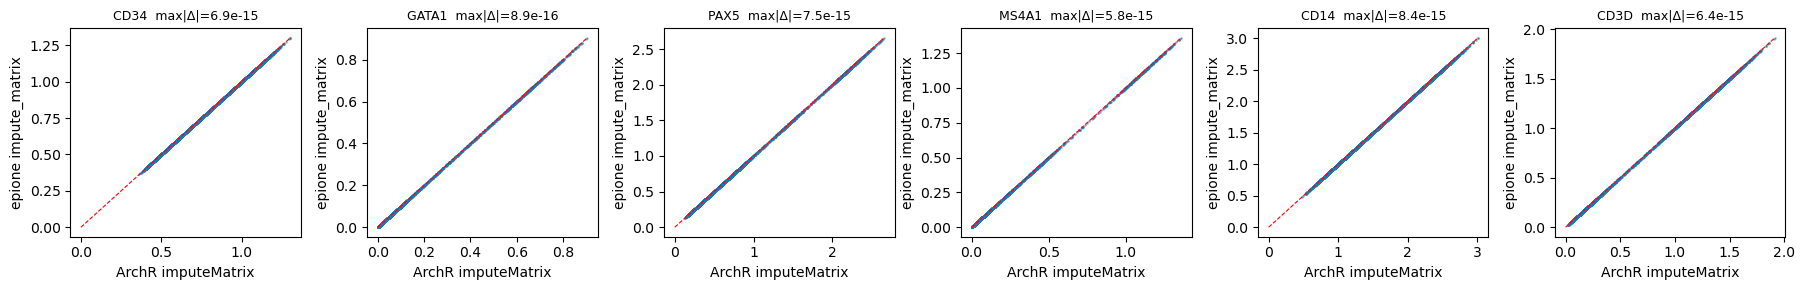

In [10]:
imp_r = pd.read_csv(REF / 'seed1_imputed.tsv.gz', sep='\t', index_col=0)
fig, axes = plt.subplots(1, len(markers), figsize=(3 * len(markers), 3))
for ax, g in zip(axes, markers):
    x = imp_r.loc[g, adata.obs_names].to_numpy()
    y = imputed[:, markers.index(g)]
    ax.scatter(x, y, s=1, alpha=0.4, rasterized=True)
    lim = [0, max(x.max(), y.max())]
    ax.plot(lim, lim, 'r--', lw=0.8)
    ax.set_title(f'{g}  max|Δ|={np.abs(x - y).max():.1e}', fontsize=9)
    ax.set_xlabel('ArchR imputeMatrix'); ax.set_ylabel('epione impute_matrix')
plt.tight_layout(); plt.show()

ArchR's own `plotEmbedding(..., imputeWeights = getImputeWeights(proj))` on the
same project, for a visual side-by-side with the MAGIC row above:

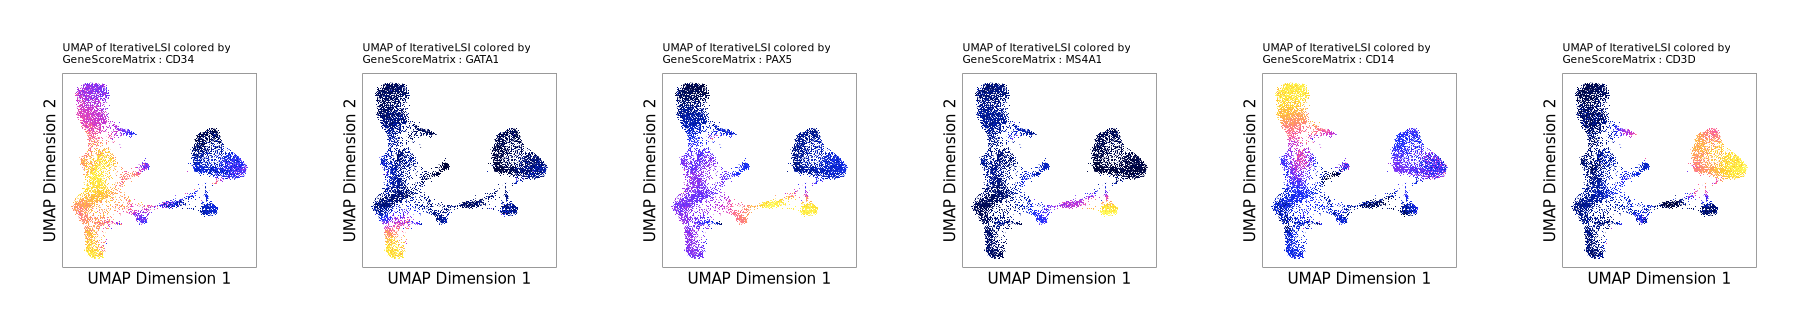

In [11]:
display(Image(filename=str(REF / 'archr_plotEmbedding_imputed.png'), width=900))

## Notes

* `rng="R"` reproduces ArchR only for `threads = 1`: with more threads ArchR draws
  each replicate's permutation inside a forked worker that does not continue the
  `set.seed()` stream. Pass ArchR's blocks through `blocks=` to match such runs.
* The weights are dense float64 blocks (`sample_cells²` × 8 bytes each, ~230 MB
  per block for the defaults), like ArchR's HDF5 weight files.
* Use `scale_dims=True` / `depth_key=` when the embedding is not already
  row-scaled and depth-filtered (e.g. a raw SVD); Epione's `iterative_lsi`
  output already has its depth-correlated components removed.